Original image size: 313x161


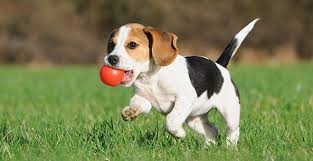

In [1]:
import cv2
import numpy as np

# Part I: Basic image IO and manipulation
im = cv2.imread("./samples/dog.jpg")
h, w, c = im.shape
print('Original image size: %sx%s' % (w, h))

import IPython.display
listOfImageNames = ['./samples/dog.jpg']

for imageName in listOfImageNames:
    IPython.display.display(IPython.display.Image(filename=imageName))

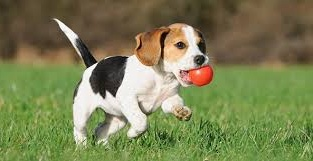

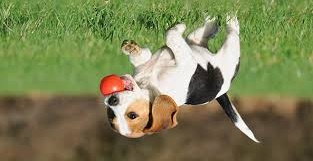

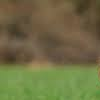

In [2]:
out_hf = cv2.flip(im, 1)
out_vf = cv2.flip(im, 0)
cv2.imwrite("./outputs/dog_hf.jpg", out_hf)
cv2.imwrite("./outputs/dog_vf.jpg", out_vf)
region = im[0:100, 0:100]
cv2.imwrite("./outputs/dog_crop.jpg", region)

import IPython.display
listOfImageNames = ['./outputs/dog_hf.jpg',
                    './outputs/dog_vf.jpg',
                    './outputs/dog_crop.jpg']

for imageName in listOfImageNames:
    IPython.display.display(IPython.display.Image(filename=imageName))

Data type is: uint8
Original image size: 100x100x3


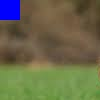

In [3]:
print('Data type is:', region.dtype)
h, w, c = region.shape
print('Original image size: %sx%sx%s' % (w, h, c))
region[0:20, 0:20] = np.array([255, 0, 0])
cv2.imwrite("./outputs/dog_crop_new.jpg", region)

import IPython.display
listOfImageNames = ["./outputs/dog_crop_new.jpg"]

for imageName in listOfImageNames:
    IPython.display.display(IPython.display.Image(filename=imageName))

Original image size: 256x192
Upsampled image size: 512x384


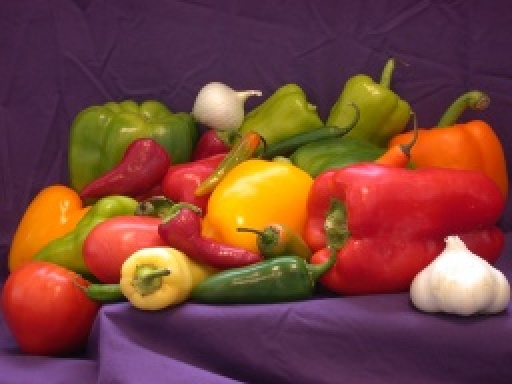

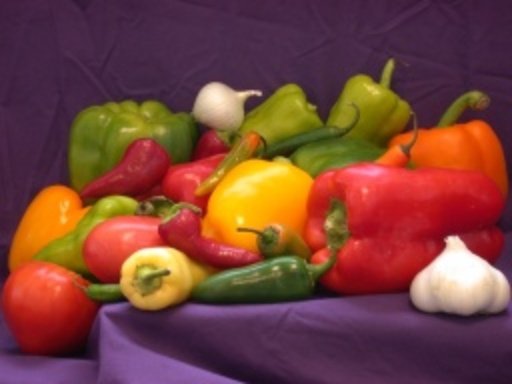

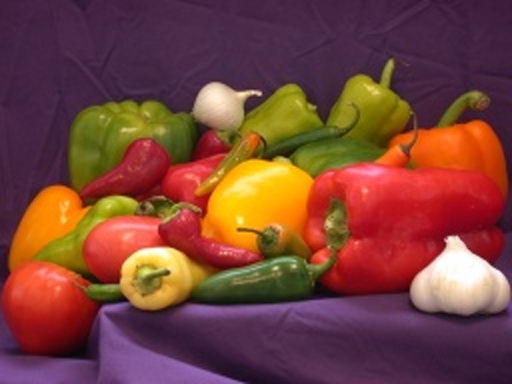

In [4]:
# Part II: Image Resampling
im = cv2.imread("./samples/peppers.jpg")
h, w, c = im.shape
print('Original image size: %sx%s' % (w, h))
up_factor = 2
im_up_nn = cv2.resize(im, (up_factor*w, up_factor*h), interpolation = cv2.INTER_NEAREST)
im_up_bl = cv2.resize(im, (up_factor*w, up_factor*h), interpolation = cv2.INTER_LINEAR)
im_up_bc = cv2.resize(im, (up_factor*w, up_factor*h), interpolation = cv2.INTER_CUBIC)
h, w, c = im_up_nn.shape
print('Upsampled image size: %sx%s' % (w, h))
cv2.imwrite("./outputs/peppers_up_nn.jpg", im_up_nn)
cv2.imwrite("./outputs/peppers_up_bl.jpg", im_up_bl)
cv2.imwrite("./outputs/peppers_up_bc.jpg", im_up_bc)

import IPython.display
listOfImageNames = ['./outputs/peppers_up_nn.jpg',
                    './outputs/peppers_up_bl.jpg',
                   './outputs/peppers_up_bc.jpg']

for imageName in listOfImageNames:
    IPython.display.display(IPython.display.Image(filename=imageName))

Original image size: 256x192
Downsampled image size: 128x96


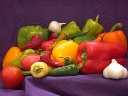

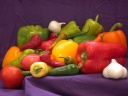

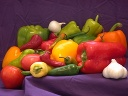

In [5]:
im = cv2.imread("./samples/peppers.jpg")
h, w, c = im.shape
print('Original image size: %sx%s' % (w, h))
down_factor = 2
im_down_nn = cv2.resize(im, (w//down_factor, h//down_factor), interpolation = cv2.INTER_NEAREST)
im_down_bl = cv2.resize(im, (w//down_factor, h//down_factor), interpolation = cv2.INTER_LINEAR)
im_down_bc = cv2.resize(im, (w//down_factor, h//down_factor), interpolation = cv2.INTER_CUBIC)
h, w, c = im_down_nn.shape
print('Downsampled image size: %sx%s' % (w, h))
cv2.imwrite("./outputs/peppers_down_nn.jpg", im_down_nn)
cv2.imwrite("./outputs/peppers_down_bl.jpg", im_down_bl)
cv2.imwrite("./outputs/peppers_down_bc.jpg", im_down_bc)

import IPython.display
listOfImageNames = ['./outputs/peppers_down_nn.jpg',
                    './outputs/peppers_down_bl.jpg',
                   './outputs/peppers_down_bc.jpg']

for imageName in listOfImageNames:
    IPython.display.display(IPython.display.Image(filename=imageName))

Original image size: 256x192


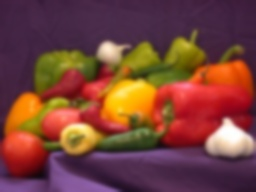

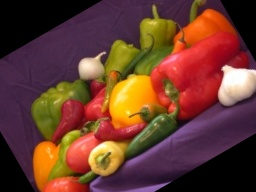

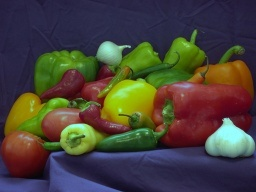

In [6]:
# Part II: Image Transforms
import numpy as np
im = cv2.imread("./samples/peppers.jpg")
h, w, c = im.shape
print('Original image size: %sx%s' % (w, h))

im_gaussian = cv2.GaussianBlur(im, (9, 9), 0)
image_center = tuple(np.array(im.shape[1::-1]) / 2)
rot_mat = cv2.getRotationMatrix2D(image_center, 30, 1.0)
im_rotated = cv2.warpAffine(im, rot_mat, im.shape[1::-1], flags=cv2.INTER_LINEAR)
im_float = im.astype(np.float32)
im_float[:, :, 2] = np.clip(im_float[:, :, 2] * 0.6, 0, 255)
im_jittered = im_float.astype(np.uint8)
cv2.imwrite("./outputs/peppers_gaussian.jpg", im_gaussian)
cv2.imwrite("./outputs/peppers_rotated_0.jpg", im_rotated)
cv2.imwrite("./outputs/peppers_jittered.jpg", im_jittered)

import IPython.display
listOfImageNames = ['./outputs/peppers_gaussian.jpg',
                    './outputs/peppers_rotated_0.jpg', 
                    './outputs/peppers_jittered.jpg']

for imageName in listOfImageNames:
    IPython.display.display(IPython.display.Image(filename=imageName))